# Phase 3 – KPI Calculations
**Analyst: Vaishali Girase**

In [3]:
import pandas as pd, numpy as np, glob, os
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

# 1) Put this notebook in the SAME folder as the CSV files (or change DATA_DIR)
DATA_DIR = "/kaggle/input/datasets/vaishaligirase/indiakart"

def load(name):
    """Finds e.g. 'orders DA.csv' or 'orders.csv' automatically."""
    hits = glob.glob(os.path.join(DATA_DIR, name + "*.csv"))
    return pd.read_csv(hits[0])

orders, items, customers = load("orders"), load("order_items"), load("customers")
products, payments = load("products"), load("payments")
returns, inventory, suppliers = load("returns"), load("inventory"), load("suppliers")

# 2) Convert dates (Indian format DD-MM-YYYY)
orders["order_date"] = pd.to_datetime(orders["order_date"], format="%d-%m-%Y")
orders["delivered_date"] = pd.to_datetime(orders["delivered_date"], format="%d-%m-%Y")
customers["registration_date"] = pd.to_datetime(customers["registration_date"], format="%d-%m-%Y")
returns["return_date"] = pd.to_datetime(returns["return_date"], format="%d-%m-%Y")

## KPI 1 – GMV (all orders, all statuses)

In [4]:
GMV = orders["final_amount"].sum()
print(f"GMV = Rs.{GMV:,.0f}  (Rs.{GMV/1e7:,.1f} Crore)")

GMV = Rs.3,147,385,545  (Rs.314.7 Crore)


## KPI 2 – Net Revenue (Delivered only)

In [5]:
delivered = orders[orders["status"]=="Delivered"]
NET = delivered["final_amount"].sum()
print(f"Net Revenue = Rs.{NET:,.0f}  ({NET/GMV*100:.1f}% of GMV)")

Net Revenue = Rs.2,053,858,612  (65.3% of GMV)


## KPI 3 – Average Order Value

In [6]:
AOV = NET/len(delivered)
print(f"AOV = Rs.{AOV:,.0f}")

AOV = Rs.63,198


## KPI 4 – Cancellation Rate (target < 10%)

In [7]:
canc = (orders["status"]=="Cancelled").mean()*100
print(f"Cancellation rate = {canc:.2f}%  ->", "ABOVE target" if canc>10 else "OK")
# Why? Link to failed payments
failed_orders = payments[payments.status=="Failed"]["order_id"]
share = orders[orders.order_id.isin(failed_orders)]["status"].eq("Cancelled").mean()
print("Share of failed-payment orders that were cancelled:", f"{share:.0%}")
print("Share of ALL cancellations explained by payment failure:", f"{len(failed_orders)/(orders.status=='Cancelled').sum():.1%}")

Cancellation rate = 11.99%  -> ABOVE target
Share of failed-payment orders that were cancelled: 100%
Share of ALL cancellations explained by payment failure: 29.2%


## KPI 5 – Return Rate (target < 8%)
The PRD formula is *return records ÷ delivered orders*. Because many return records sit on non-delivered orders (a data-quality issue from Phase 1) I show both versions.

In [8]:
rr_prd = len(returns)/len(delivered)*100
rr_status = (orders["status"]=="Returned").sum()/len(delivered)*100
print(f"Return rate (PRD formula: return records / delivered orders) = {rr_prd:.1f}%")
print(f"Return rate (orders with status = Returned / delivered)     = {rr_status:.1f}%")

Return rate (PRD formula: return records / delivered orders) = 30.8%
Return rate (orders with status = Returned / delivered)     = 12.1%


## KPI 6 – Customer Lifetime Value by segment (avg total_spent)

In [9]:
clv = customers.groupby("segment")["total_spent"].mean().sort_values(ascending=False).round(0)
print(clv)
print("\nPremium / Regular ratio: %.2fx (benchmark: 3x)" % (clv["Premium"]/clv["Regular"]))

segment
Premium    532,735.00
Regular    361,871.00
New        274,866.00
Budget     186,179.00
Inactive    32,249.00
Name: total_spent, dtype: float64

Premium / Regular ratio: 1.47x (benchmark: 3x)


## KPI 7 – Month-over-Month GMV growth

In [10]:
orders["month"]=orders["order_date"].dt.to_period("M")
gm = orders.groupby("month")["final_amount"].sum()
mom = (gm.pct_change()*100).round(1)
pd.DataFrame({"GMV":gm.round(0),"MoM_%":mom}).tail(12)
# NOTE: Jun-2023 and Jun-2025 are partial months, so their growth figures look extreme.

,GMV,MoM_%
month,,
2024-07,"127,028,266.00",2.70
2024-08,"131,923,460.00",3.90
2024-09,"130,525,274.00",-1.10
2024-10,"133,518,341.00",2.30
2024-11,"126,264,142.00",-5.40
2024-12,"133,089,460.00",5.40
2025-01,"137,929,117.00",3.60
2025-02,"114,116,741.00",-17.30
2025-03,"136,493,234.00",19.60


## KPI 8 – Category revenue share (concentration risk if > 60%)

In [11]:
c = items.groupby("category")["total_price"].sum()
share = (c/c.sum()*100).round(1).sort_values(ascending=False)
share

category
Electronics        57.40
Sports & Fitness   17.40
Home & Kitchen      8.50
Fashion             5.20
Automotive          4.30
Office Supplies     3.30
Toys & Baby         1.60
Beauty & Health     1.20
Grocery             0.70
Books               0.50
Name: total_price, dtype: float64

## KPI 9 – Payment Failure Rate (target < 2%)

In [12]:
pf=(payments["status"]=="Failed").mean()*100
print(f"Payment failure rate = {pf:.2f}%")
print((payments.assign(f=payments.status=="Failed").groupby("gateway")["f"].mean()*100).round(2).sort_values())

Payment failure rate = 3.50%
gateway
BillDesk     3.17
Paytm        3.31
PhonePe      3.31
PayU         3.47
Google Pay   3.69
CCAvenue     3.72
Razorpay     3.80
Name: f, dtype: float64


## KPI 10 – Inventory Fill Rate (target > 95%)

In [13]:
fill=(inventory["status"]=="In Stock").mean()*100
print(f"Fill rate = {fill:.1f}%  | Low stock: {(inventory.status=='Low Stock').sum()} | Out of stock: {(inventory.status=='Out of Stock').sum()}")

Fill rate = 92.2%  | Low stock: 76 | Out of stock: 2


## KPI Scorecard

| KPI | Result | Target | Status |
|---|---|---|---|
| GMV | ₹314.7 Cr | – | – |
| Net Revenue | ₹205.4 Cr (65.3% of GMV) | – | – |
| AOV | ₹63,198 | – | – |
| Cancellation rate | 11.99% | < 10% | ❌ |
| Return rate (PRD formula) | 30.8% (12.1% by Returned status) | < 8% | ❌ |
| Premium CLV vs Regular | ₹5.33 L vs ₹3.62 L = 1.47x | 3x | ❌ |
| Top category share | Electronics 57.4% | < 60% | ⚠️ close |
| Payment failure | 3.50% | < 2% | ❌ |
| Fill rate | 92.2% | > 95% | ❌ |

## BONUS – Cohort analysis (retention by registration month)

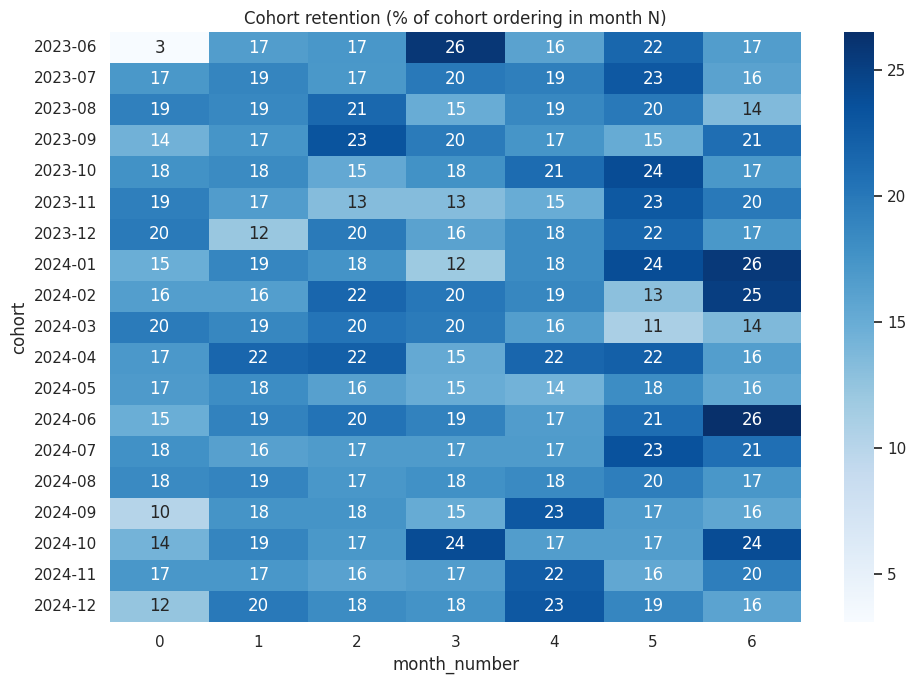

In [14]:
x = orders.merge(customers[["customer_id","registration_date"]], on="customer_id")
x["cohort"] = x["registration_date"].dt.to_period("M")
x["order_month"] = x["order_date"].dt.to_period("M")
x["month_number"] = (x["order_month"]-x["cohort"]).apply(lambda d: d.n)
# keep only valid orders (placed on/after registration) - see Phase 1 data-quality note
valid = x[x["month_number"]>=0]
cohort = valid.pivot_table(index="cohort", columns="month_number", values="customer_id", aggfunc="nunique")
size = customers.groupby(customers["registration_date"].dt.to_period("M")).size()
retention = cohort.div(size, axis=0).iloc[:, :7].round(3)*100
# Only cohorts that registered inside the data window (Jun-2023 onwards) and have enough history
retention = retention.loc[retention.index >= pd.Period("2023-06")]
retention = retention.loc[retention.index <= pd.Period("2024-12")]
plt.figure(figsize=(10,7)); sns.heatmap(retention, annot=True, fmt=".0f", cmap="Blues"); plt.title("Cohort retention (% of cohort ordering in month N)")
os.makedirs("charts", exist_ok=True); plt.tight_layout(); plt.savefig("charts/11_cohort.png", dpi=130); plt.show()